In [1]:
import numpy as np
import pandas as pd
from matplotlib import rc, rcParams
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
import textwrap
from scipy.stats import dunnett, levene, bartlett, tukey_hsd, kruskal
from sklearn.cluster import KMeans
from pathlib import Path

In [2]:
path2figs = Path("figs")
path2figs.mkdir(parents=True, exist_ok=True)
path2data = Path("../data")
# per-cell statistics for the pulse experiment (classes A/B)
path2stats = path2data / "pulse_combined_dataframe.csv"
# hand-corrected acquisition time (h) for each pulse frame
path2times = path2data / "pulse_times.csv"

In [3]:
# Load dataframe, restrict to only green cells:
df = pd.read_csv(path2stats)
_drop_cols = ['color', 'red', 'green', 'entropy', 'parent', 'intensity', 'x_cm', 'y_cm', 'dx', 'dy', 'd_total']
df = df[df['color'] == 'g'].drop(columns=_drop_cols).reset_index(drop=True)

df = df[df['area'] >= 100].reset_index(drop=True)
_drop_cols = ['area']
df = df.drop(columns=_drop_cols).reset_index(drop=True)

In [4]:
df_n_green_time = pd.DataFrame()
df_n_frames = df.groupby(['vclass', 'vidx'])['frame'].nunique().reset_index(name='n_frames')
for idx, row in df_n_frames.iterrows():
    vclass, vidx, n_frames = row.vclass, row.vidx, row.n_frames

    row = []
    n_green_max = df[(df.vclass == vclass) & (df.vidx == vidx) & (df.frame <= n_frames)]['label'].nunique()
    for frame in range(n_frames):
        n_green_in_frame = df[(df.vclass == vclass) & (df.vidx == vidx) & (df.frame == frame)]['label'].nunique()
        n_green_cdf = df[(df.vclass == vclass) & (df.vidx == vidx) & (df.frame <= frame)]['label'].nunique() / n_green_max

        row.append({
            'vclass': vclass, 
            'vidx': vidx, 
            'frame': frame, 
            'n_green_in_frame': n_green_in_frame, 
            'n_green_cdf': n_green_cdf})
    # end for

    df_n_green_time = pd.concat([df_n_green_time, pd.DataFrame(row)])
# end for

df_n_green_time['n_green_pdf'] = df_n_green_time.groupby(['vclass', 'vidx'])['n_green_cdf'].transform(lambda x: x.diff()).fillna(0)
df_n_green_time['n_green_pdf'] = (
    df_n_green_time.groupby(['vclass', 'vidx'])['n_green_pdf']
    .transform(lambda x: x / x.sum())
)

df_n_green_time['delta_n_green_in_frame'] = df_n_green_time.groupby(['vclass', 'vidx'])['n_green_in_frame'].transform(lambda x: x - x.iloc[0]).fillna(0)

In [5]:
# attach the hand-corrected time (h) of each frame. pulse_times.csv also stores the green
# counts it was built from; check they agree with the counts recomputed above.
df_pulse_times = pd.read_csv(path2times)
df_n_green_time_corrected = df_n_green_time.drop(columns=['n_green_cdf', 'n_green_pdf']).merge(
    df_pulse_times[['vclass', 'vidx', 'frame', 'time (h)']],
    on=['vclass', 'vidx', 'frame'], how='left', validate='one_to_one') \
    .sort_values(by=['vclass', 'vidx', 'frame']).reset_index(drop=True)
assert df_n_green_time_corrected['time (h)'].notna().all()

_check = df_n_green_time_corrected.merge(df_pulse_times, on=['vclass', 'vidx', 'frame'], suffixes=('', '_csv'))
assert len(_check) == len(df_pulse_times) == len(df_n_green_time_corrected)
assert (_check['n_green_in_frame'] == _check['n_green_in_frame_csv']).all()
assert (_check['delta_n_green_in_frame'] == _check['delta_n_green_in_frame_csv']).all()

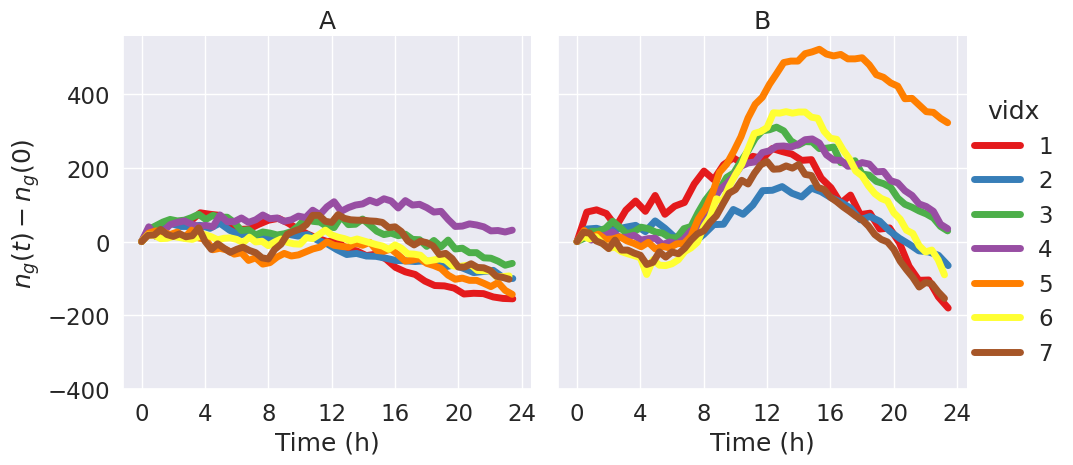

In [6]:
def _():
    sns.set_theme(font_scale=1.5)
    g = sns.relplot(data=df_n_green_time_corrected, kind='line', 
                x='time (h)', y='delta_n_green_in_frame', 
                col='vclass', col_order=['A', 'B'],
                hue='vidx',
                lw=5,
                palette='Set1')

    # set custom col titles
    col_titles = [
        "A", 
        "B"
    ]
    for ax, title in zip(g.axes.flat, col_titles):
        ax.set_title(title)
    g.set(xlabel='Time (h)', ylabel=r'$n_g(t) - n_g(0)$')
    plt.xticks([0, 4, 8, 12, 16, 20, 24])
    plt.yticks([-400, -200, 0, 200, 400])

    plt.savefig(path2figs / 'pulse_n_alive_green.pdf')

    return g


_()

### The same, but for unique red cells in each video

In [7]:
# Load red cells with the same processing applied to the green cells above
df_red = pd.read_csv(path2stats)
_drop_cols_red = ['color', 'red', 'green', 'entropy', 'parent', 'intensity', 'x_cm', 'y_cm', 'dx', 'dy', 'd_total']
df_red = df_red[df_red['color'] == 'r'].drop(columns=_drop_cols_red).reset_index(drop=True)

df_red = df_red[df_red['area'] >= 100].reset_index(drop=True)
df_red = df_red.drop(columns=['area']).reset_index(drop=True)

In [8]:
df_n_red_time = pd.DataFrame()
df_red_n_frames = df_red.groupby(['vclass', 'vidx'])['frame'].nunique().reset_index(name='n_frames')
for idx, row in df_red_n_frames.iterrows():
    vclass, vidx, n_frames = row.vclass, row.vidx, row.n_frames

    # subset once per video (red has ~6x more cells than green) to avoid rescanning
    # the full dataframe on every frame
    df_vid = df_red[(df_red.vclass == vclass) & (df_red.vidx == vidx)]

    row = []
    n_red_max = df_vid[df_vid.frame <= n_frames]['label'].nunique()
    for frame in range(n_frames):
        n_red_in_frame = df_vid[df_vid.frame == frame]['label'].nunique()
        n_red_cdf = df_vid[df_vid.frame <= frame]['label'].nunique() / n_red_max

        row.append({
            'vclass': vclass, 
            'vidx': vidx, 
            'frame': frame, 
            'n_red_in_frame': n_red_in_frame, 
            'n_red_cdf': n_red_cdf})
    # end for

    df_n_red_time = pd.concat([df_n_red_time, pd.DataFrame(row)])
# end for

df_n_red_time['n_red_pdf'] = df_n_red_time.groupby(['vclass', 'vidx'])['n_red_cdf'].transform(lambda x: x.diff()).fillna(0)
df_n_red_time['n_red_pdf'] = (
    df_n_red_time.groupby(['vclass', 'vidx'])['n_red_pdf']
    .transform(lambda x: x / x.sum())
)

df_n_red_time['delta_n_red_in_frame'] = df_n_red_time.groupby(['vclass', 'vidx'])['n_red_in_frame'].transform(lambda x: x - x.iloc[0]).fillna(0)

# attach the same time (h) correction used for the green cells (frames align exactly)
df_n_red_time_corrected = df_n_red_time.merge(
    df_n_green_time_corrected[['vclass', 'vidx', 'frame', 'time (h)']],
    on=['vclass', 'vidx', 'frame'], how='left')

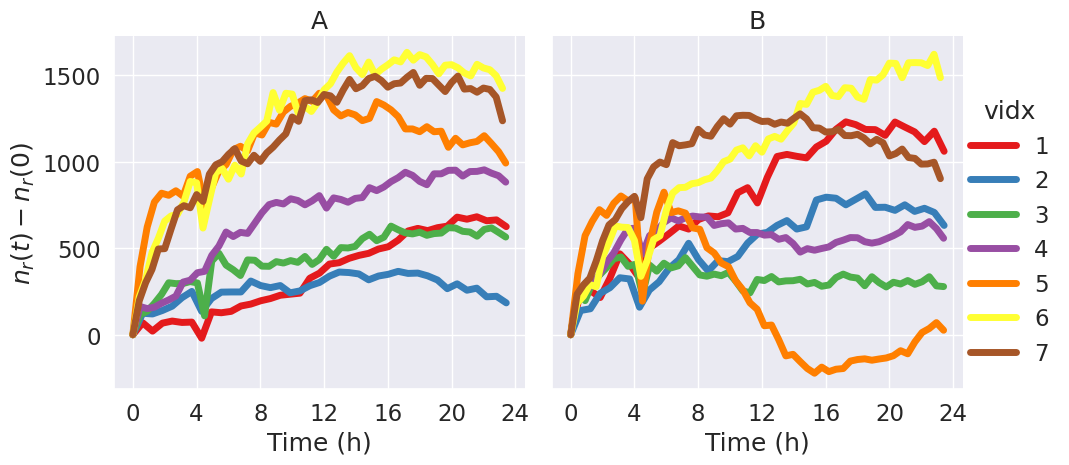

In [9]:
def _():
    sns.set_theme(font_scale=1.5)
    g = sns.relplot(data=df_n_red_time_corrected, kind='line', 
                x='time (h)', y='delta_n_red_in_frame', 
                col='vclass', col_order=['A', 'B'],
                hue='vidx',
                lw=5,
                palette='Set1')

    # set custom col titles
    col_titles = [
        "A", 
        "B"
    ]
    for ax, title in zip(g.axes.flat, col_titles):
        ax.set_title(title)
    g.set(xlabel='Time (h)', ylabel=r'$n_r(t) - n_r(0)$')
    plt.xticks([0, 4, 8, 12, 16, 20, 24])
    # red counts are much larger than green, so let the y-axis auto-scale

    plt.savefig(path2figs / 'pulse_n_alive_red.pdf')

    return g


_()

### The green fraction of all cells, g / (g + r), relative to its initial value

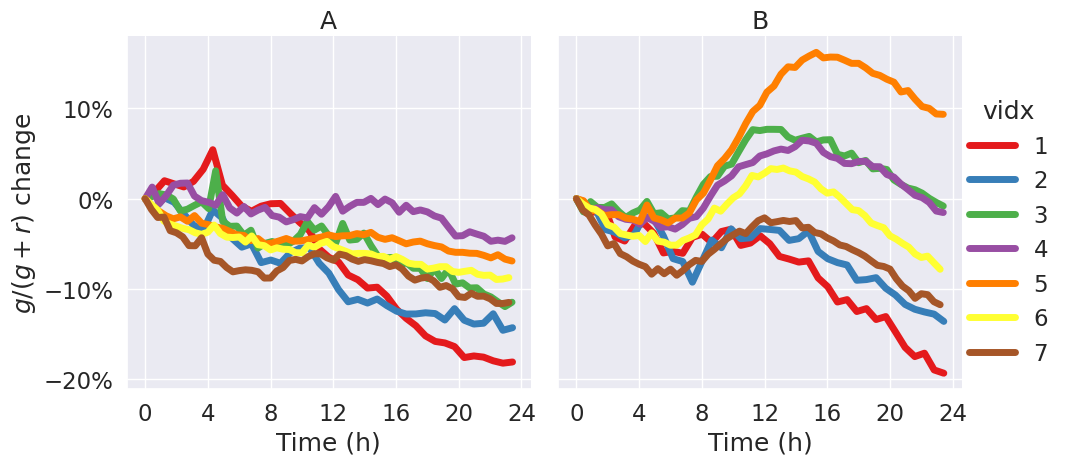

In [10]:
from matplotlib.ticker import PercentFormatter

# green cells as a fraction of ALL cells in the frame, g / (g + r), combining the
# time-corrected green counts (pulse_times.csv) with the red counts computed above
df_frac_green = df_n_green_time_corrected[['vclass', 'vidx', 'frame', 'time (h)', 'n_green_in_frame']].merge(
    df_n_red_time[['vclass', 'vidx', 'frame', 'n_red_in_frame']],
    on=['vclass', 'vidx', 'frame'], how='outer')
df_frac_green = df_frac_green.sort_values(['vclass', 'vidx', 'frame']).reset_index(drop=True)

df_frac_green['frac_green'] = df_frac_green['n_green_in_frame'] / (df_frac_green['n_green_in_frame'] + df_frac_green['n_red_in_frame'])

# change in the green fraction relative to each replicate's first frame
df_frac_green['delta_frac_green'] = df_frac_green.groupby(['vclass', 'vidx'])['frac_green'].transform(lambda x: x - x.iloc[0])


def _():
    sns.set_theme(font_scale=1.5)
    g = sns.relplot(data=df_frac_green, kind='line', 
                x='time (h)', y='delta_frac_green', 
                col='vclass', col_order=['A', 'B'],
                hue='vidx',
                lw=5,
                palette='Set1')

    # set custom col titles
    col_titles = [
        "A", 
        "B"
    ]
    for ax, title in zip(g.axes.flat, col_titles):
        ax.set_title(title)
    g.set(xlabel='Time (h)', ylabel=r'$g/(g+r)$ change')
    for ax in g.axes.flat:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    plt.xticks([0, 4, 8, 12, 16, 20, 24])

    plt.savefig(path2figs / 'pulse_green_fraction_change.pdf')

    return g


_()

In [11]:
# save one row per sample and time point: green/red counts, their change from the first frame,
# and g/(g+r) with its change
df_times = df_frac_green.copy()
for c in ['n_green_in_frame', 'n_red_in_frame']:
    df_times[f'delta_{c}'] = df_times[c] - df_times.groupby(['vclass', 'vidx'])[c].transform('first')
df_times = df_times[['vclass', 'vidx', 'frame', 'time (h)', 'n_green_in_frame', 'n_red_in_frame',
                     'delta_n_green_in_frame', 'delta_n_red_in_frame', 'frac_green', 'delta_frac_green']]
df_times.to_csv(path2data / 'pulse_times_full.csv', index=False)